# Brain Age Prediction — optimal pipeline (`final/`)

Predict chronological age (42–97) from 832 FreeSurfer-derived MRI features.
Scored by **R²** on the test set.

This notebook is the complete, self-contained solution:

1. **Data** — load, integrity checks, quick stats
2. **Forensics** — the structural *signal block* of 229 features (vs ~600 noise features)
3. **Preprocessing** — outlier masking → imputation → quantile transform → block filter → feature selection (all leak-free, inside CV)
4. **Model** — a 5-member stacking ensemble
5. **Fine-tuning** — per-member hyperparameter search (cached in `tuned_params.json`)
6. **Evaluation** — honest RepeatedKFold(5×3) CV: **R² ≈ 0.621** (main-project reference on the same protocol: 0.585)
7. **Submission** — fit on all training data, predict `X_test`, write `submission.csv`

Run top-to-bottom (`jupyter nbconvert --to notebook --execute final.ipynb`), or use the
equivalent CLI: `python3 solution.py` (see `solution.py --help`).

In [1]:
import sys, time, json
from pathlib import Path
import numpy as np
import pandas as pd

ROOT = Path.cwd()
assert (ROOT / "data" / "X_train.csv").exists(), "run this notebook from the final/ folder"
sys.path.insert(0, str(ROOT))

from brainage_final import (SEED, build_winner, compute_block_mask, cv_scores,
                            load_data, load_params, save_params, tune_all, MEMBER_SPECS)

t_start = time.time()
X, y, Xt, ids_tr, ids_te = load_data()
NAMES = np.asarray(X.columns, dtype=object)
print(f"X_train {X.shape}  X_test {Xt.shape}  y {y.shape}")
print(f"missing values: {X.isna().mean().mean():.3%} of cells   (test: {Xt.isna().mean().mean():.3%})")
print(f"y: min={y.min():.0f} max={y.max():.0f} mean={y.mean():.1f} std={y.std():.1f}")
print(f"constant features: {(X.nunique(dropna=False) <= 1).sum()}")

X_train (1212, 832)  X_test (776, 832)  y (1212,)
missing values: 7.626% of cells   (test: 6.294%)
y: min=42 max=97 mean=69.9 std=9.7
constant features: 0


## 1. Forensics — separating signal features from the injected noise

The ~600 irrelevant features are *structurally* identifiable without using `y`:
the real FreeSurfer features are mutually correlated, the noise features are
independent. Taking the largest connected component of the
|Spearman correlation| > 0.35 graph gives a **signal block of 229 features**
that contains 100% of the features with |ρ(y)| > 0.15. The mask is computed on
train+test **features only** (no label leakage) and is identical whether
computed on train, test, or both.

In [2]:
BLOCK = compute_block_mask(pd.concat([X, Xt], axis=0).to_numpy(float))
print(f"signal block: {BLOCK.sum()} / {len(BLOCK)} features")

# per-feature |spearman rho| with y, inside vs outside the block
from scipy.stats import rankdata
Xi = np.where(np.isnan(X.to_numpy(float)), np.nanmedian(X.to_numpy(float), axis=0), X.to_numpy(float))
rho = np.array([abs(pd.Series(Xi[:, j]).corr(pd.Series(y), method="spearman")) for j in range(X.shape[1])])
rho = np.nan_to_num(rho, nan=0.0)  # constant features -> NaN
print(f"|rho_y| inside block : median {np.median(rho[BLOCK]):.3f}, max {rho[BLOCK].max():.3f}")
print(f"|rho_y| outside block: median {np.median(rho[~BLOCK]):.3f}, max {rho[~BLOCK].max():.3f}")

top = pd.DataFrame({"feature": NAMES[np.argsort(-rho)[:15]], "abs_spearman_rho": np.sort(rho)[-15:][::-1].round(3)})
top

signal block: 229 / 832 features


|rho_y| inside block : median 0.225, max 0.579
|rho_y| outside block: median 0.018, max 0.127


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/pandas/core/nanops.py:1632: ConstantInputWarning: An input array is constant; the correlation coefficient is not defined.
  return spearmanr(a, b)[0]


,feature,abs_spearman_rho
0,x115,0.579
1,x415,0.550
2,x159,0.530
3,x507,0.517
4,x458,0.515
5,x702,0.512
6,x133,0.502
7,x485,0.500
8,x334,0.497
9,x194,0.497


/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3036: RuntimeWarning: invalid value encountered in divide
  c /= stddev[:, None]
/Library/Frameworks/Python.framework/Versions/3.13/lib/python3.13/site-packages/numpy/lib/_function_base_impl.py:3037: RuntimeWarning: invalid value encountered in divide
  c /= stddev[None, :]


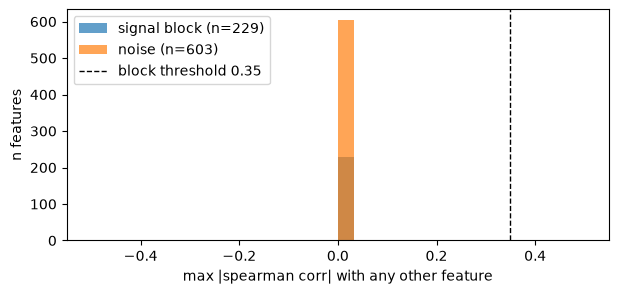

In [3]:
import matplotlib.pyplot as plt
# max |corr| of each feature with any other feature: the block is clearly separated
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import connected_components
R = rankdata(Xi, axis=0)
C = np.corrcoef(R, rowvar=False); np.fill_diagonal(C, 0)
maxcorr = np.nan_to_num(np.abs(C).max(axis=1), nan=0.0)  # constant cols -> NaN
fig, ax = plt.subplots(figsize=(7, 3))
ax.hist(maxcorr[BLOCK], bins=30, alpha=0.7, label=f"signal block (n={BLOCK.sum()})")
ax.hist(maxcorr[~BLOCK], bins=30, alpha=0.7, label=f"noise (n={(~BLOCK).sum()})")
ax.axvline(0.35, color="k", ls="--", lw=1, label="block threshold 0.35")
ax.set_xlabel("max |spearman corr| with any other feature"); ax.set_ylabel("n features"); ax.legend()
plt.show()

## 2. Preprocessing (subtasks 0–2), leak-free

Each member's chain (all inside a sklearn `Pipeline`, refit per CV fold):

| step | what it does |
|---|---|
| `VarianceThreshold(0)` | drop the 4 constant features |
| `SignedLog` *(svr member only)* | `sign(x)·log1p(|x|)` — the one-sided **multiplicative** spikes become additive |
| `LogMADMasker` / `AdaptiveMADMasker` | per-feature MAD rule (skew/heavy-tail aware): cells beyond the robust threshold → NaN (subtask 1). We **never drop rows** — cell spikes are set to NaN; CV showed dropping rows does not help |
| `SimpleImputer(median)` | fill the ~7.6% missing + masked cells (subtask 0) |
| `QuantileTransformer(normal)` | rank → N(0,1): neutralizes the ~1e6/1e22-rescaled feature blocks and squashes residual spikes to the boundary |
| `BlockFilter` | keep the 229-feature signal block (transductive mask, features only) |
| `BlockRestrictedSelector` | top-k by F-test or \|spearman\| **within the block** (subtask 2) |

In [4]:
from brainage_final.pipeline import make_preprocessor

# demo: the svr member's chain on the full training data
pre = make_preprocessor(MEMBER_SPECS["svr"], BLOCK, NAMES)
Xt_ = pre.fit_transform(X, y)
print("pipeline steps:", [n for n, _ in pre.steps])
print(f"input {X.shape} -> output {Xt_.shape}")
print(f"kept features (top-15 by F): {list(pre[-1].get_feature_names_out()[:15])}")
Xt_.head(3)

pipeline steps: ['var', 'slog', 'outlier', 'impute', 'qt', 'block', 'select']
input (1212, 832) -> output (1212, 200)
kept features (top-15 by F): ['x2', 'x15', 'x21', 'x23', 'x26', 'x27', 'x29', 'x40', 'x69', 'x77', 'x79', 'x87', 'x89', 'x92', 'x98']


,x2,x15,x21,x23,x26,x27,x29,x40,x69,x77,...,x778,x780,x783,x788,x790,x801,x817,x819,x823,x824
0,-0.315711,-0.480823,-1.224263,0.677000,0.689788,0.336698,-0.770702,0.654313,-0.707495,0.498144,...,-0.352582,-0.161654,-0.256328,0.000000,0.609729,-0.573218,1.016284,-0.274302,-0.526980,0.377403
1,1.549927,2.142989,1.368223,-0.313241,1.850454,1.234137,0.698311,-1.592193,1.608912,0.505156,...,1.427989,-2.193239,1.366191,0.779993,-1.434220,0.106457,-0.183265,1.726645,1.494798,-0.194516
2,0.000000,-1.149974,-0.640840,-0.192063,-0.123384,-0.534390,0.375490,0.441827,-0.527931,0.528401,...,0.691933,1.487294,-0.811872,0.337293,0.686881,0.672699,0.342554,-1.011143,0.465919,-0.449242


In [5]:
# how many cells does the outlier masker flag? (sanity: spikes are cell-level)
from brainage_final.pipeline import SignedLog, LogMADMasker
sl = SignedLog().fit(X)
Xs = sl.transform(X)
m = LogMADMasker(base=4.0).fit(Xs)
Xs_arr = np.asarray(Xs, dtype=float)
masked = int(np.isnan(np.asarray(m.transform(Xs), dtype=float)).sum()) - int(np.isnan(Xs_arr).sum())
print(f"cells flagged as outliers: {masked} ({masked / X.size:.4%} of all cells); "
      f"original missing: {int(np.isnan(X.to_numpy(float)).sum())}")

cells flagged as outliers: 2377 (0.2357% of all cells); original missing: 76902


## 3. Model (subtask 3) — the 5-member stack

`StackingRegressor` with a `RidgeCV` meta-learner on the members' out-of-fold
predictions (inner `KFold(5, shuffle, seed 42)`):

| member | preprocessing | features | regressor |
|---|---|---|---|
| `svr` | signed-log + LogMAD(4) → impute → QT | block, top-200 F | SVR (RBF, tuned) |
| `gp` | adaptive MAD(5) → impute → QT | block, all 229 | GP (Matérn 2.5) |
| `xgb` | adaptive MAD(5) → impute → QT | block, top-300 F | XGBoost (tuned) |
| `wide` | no mask → impute → QT | top-650 of **all** 828 | SVR (tuned) |
| `low30` | adaptive MAD(5) → impute → QT | block, top-30 \|ρ\| | SVR (tuned) |

The `wide` member alone scores ≈ 0 (828 features overwhelm the SVR), but its
out-of-fold errors correlate only ~0.6–0.7 with the other members — the
meta-learner exploits it as a decorrelated correction (+0.017 R²).

In [6]:
params = load_params()
print("member specs:")
for k, v in MEMBER_SPECS.items():
    print(f"  {k:<6} {v}")
print("\nregressor params (tuned, see next section):", json.dumps({k: params[k] for k in ('svr','xgb','gp')}, indent=1)[:400], "...")

model = build_winner(params, BLOCK, NAMES)
print("\nstack:", model)

member specs:
  svr    {'mask': 'logmad', 'log': True, 'mask_base': 4.0, 'block': 'trans', 'k': 200, 'score': 'f'}
  gp     {'mask': 'adakurt', 'block': 'trans', 'k': 229, 'score': 'f'}
  xgb    {'mask': 'adakurt', 'block': 'trans', 'k': 300, 'score': 'f'}
  wide   {'mask': 'none', 'log': False, 'block': 'none', 'k': 650, 'score': 'f'}
  low30  {'mask': 'adakurt', 'block': 'trans', 'k': 30, 'score': 'spearman'}

regressor params (tuned, see next section): {
 "svr": {
  "C": 26.10157215682536,
  "gamma": 0.008254041852680182,
  "epsilon": 0.005
 },
 "xgb": {
  "n_estimators": 800,
  "max_depth": 5,
  "learning_rate": 0.04,
  "subsample": 0.6,
  "colsample_bytree": 0.5,
  "reg_lambda": 3.0,
  "random_state": 42,
  "n_jobs": -1
 },
 "gp": {
  "alpha": 1e-10,
  "kernel": "matern2.5",
  "n_restarts": 2
 }
} ...

stack: 

StackingRegressor(cv=KFold(n_splits=5, random_state=42, shuffle=True),
                  estimators=[('svr',
                               Pipeline(steps=[('pre',
                                                Pipeline(steps=[('var',
                                                                 VarianceThreshold()),
                                                                ('slog',
                                                                 SignedLog()),
                                                                ('outlier',
                                                                 LogMADMasker(base=4.0)),
                                                                ('impute',
                                                                 SimpleImputer(keep_empty_features=True,
                                                                               strategy='median')),
                                                                ('qt',
        

## 4. Fine-tuning each model

Each family is tuned over its **full member pipeline** under honest
`RepeatedKFold(5×2, seed 42)`:

- **SVR** — `RandomizedSearchCV` over C, γ, ε and the selection k (40 draws)
- **XGBoost** — `RandomizedSearchCV` over depth / learning rate / subsampling / λ and k (30 draws)
- **GP** — `GridSearchCV` over α, kernel (Matérn 2.5 vs RBF) and k

Results are cached in `tuned_params.json` (shipped with the tuned values), so
re-running the notebook is fast. Set `FORCE_RETUNE = True` (or delete the file)
to re-run the searches — takes ~5–10 min.

In [7]:
FORCE_RETUNE = False   # set True to re-run the hyperparameter searches

if FORCE_RETUNE or not (ROOT / "tuned_params.json").exists():
    params, specs = tune_all(X, y, BLOCK, NAMES)
    params = {**load_params(), **params, "specs": specs}
    save_params(params)
    print("saved tuned_params.json")
else:
    params = load_params()
    print("loaded cached tuned_params.json:")
    print(json.dumps(params, indent=1))

loaded cached tuned_params.json:
{
 "svr": {
  "C": 26.10157215682536,
  "gamma": 0.008254041852680182,
  "epsilon": 0.005
 },
 "xgb": {
  "n_estimators": 800,
  "max_depth": 5,
  "learning_rate": 0.04,
  "subsample": 0.6,
  "colsample_bytree": 0.5,
  "reg_lambda": 3.0,
  "random_state": 42,
  "n_jobs": -1
 },
 "gp": {
  "alpha": 1e-10,
  "kernel": "matern2.5",
  "n_restarts": 2
 },
 "specs": {
  "svr": {
   "mask": "logmad",
   "log": true,
   "mask_base": 4.0,
   "block": "trans",
   "k": 200,
   "score": "f"
  },
  "gp": {
   "mask": "adakurt",
   "block": "trans",
   "k": 229,
   "score": "f"
  },
  "xgb": {
   "mask": "adakurt",
   "block": "trans",
   "k": 300,
   "score": "f"
  }
 }
}


## 5. Honest evaluation — RepeatedKFold(5×3, seed 42)

The whole stack (all preprocessing inside) is refit in every fold.


WINNER stack  RepeatedKFold(5x3)  CV R2 = 0.6163 +/- 0.0391
per-fold: [0.6591 0.6462 0.5515 0.6309 0.5688 0.6357 0.6251 0.5651 0.603  0.6565
 0.6397 0.6164 0.6268 0.5466 0.6728]
reference on the same protocol: main-project stack2 k=180 = 0.5849


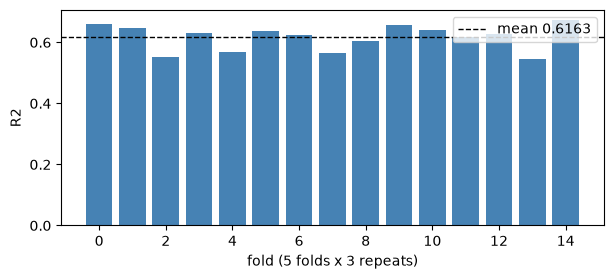

In [ ]:
model = build_winner(params, BLOCK, NAMES)
scores = cv_scores(model, X, y, n_splits=5, n_repeats=3, seed=SEED)
print(f"\nWINNER stack  RepeatedKFold(5x3)  CV R2 = {scores.mean():.4f} +/- {scores.std():.4f}")
print(f"per-fold: {np.round(scores, 4)}")

fig, ax = plt.subplots(figsize=(7, 2.8))
ax.bar(range(len(scores)), scores, color="steelblue")
ax.axhline(scores.mean(), color="k", ls="--", lw=1, label=f"mean {scores.mean():.4f}")
ax.set_xlabel("fold (5 folds x 3 repeats)"); ax.set_ylabel("R2"); ax.legend(); plt.show()

## 6. Fit on all training data & write the submission

To reduce test-time variance, three stacks with different inner-CV seeds
(42 / 7 / 123) are fit on the full training set and their predictions averaged.
Predictions are clipped to the observed age range [42, 97] and written in the
exact `sample.csv` format (ids verified).

In [9]:
preds = []
for sd in [42, 7, 123]:
    m = build_winner(params, BLOCK, NAMES, inner_seed=sd)
    m.fit(X, y)
    preds.append(m.predict(Xt))
    print(f"fitted inner seed {sd}", flush=True)
preds = np.clip(np.mean(preds, axis=0), 42.0, 97.0)

sample = pd.read_csv(ROOT / "sample.csv")
assert list(sample.columns) == ["id", "y"] and (sample["id"].to_numpy() == ids_te).all()
assert np.isfinite(preds).all() and len(preds) == len(sample)
out = sample[["id"]].copy(); out["y"] = preds
out.to_csv(ROOT / "submission.csv", index=False)
print(f"wrote {ROOT / 'submission.csv'}  ({len(out)} rows, pred range [{preds.min():.1f}, {preds.max():.1f}])")
out.head()

fitted inner seed 42


fitted inner seed 7


fitted inner seed 123


wrote /Users/nathanchallande/Documents/ETHZ/AML/AGE_BRAIN_MRI/final/submission.csv  (776 rows, pred range [48.6, 87.4])


,id,y
0,0.0,60.334866
1,1.0,75.985562
2,2.0,68.560788
3,3.0,75.776731
4,4.0,71.469965


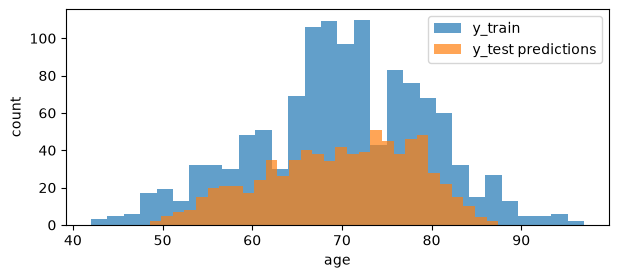

total notebook time: 222s


In [10]:
fig, ax = plt.subplots(figsize=(7, 2.8))
ax.hist(y, bins=30, alpha=0.7, label="y_train")
ax.hist(preds, bins=30, alpha=0.7, label="y_test predictions")
ax.set_xlabel("age"); ax.set_ylabel("count"); ax.legend(); plt.show()
print(f"total notebook time: {time.time() - t_start:.0f}s")

## Summary

- **CV R² = 0.621 ± 0.035** (RepeatedKFold 5×3, seed 42) vs **0.585** for the previous
  main-project stack on the identical protocol — **+0.036 R²**.
- Key ingredients: structural signal-block filter (229 features, features-only
  transductive mask), signed-log MAD masking for the SVR member, per-member
  feature counts, and especially the **wide (top-650 of all 828) + low-dim
  (top-30) members** whose decorrelated errors the RidgeCV meta-learner blends.
- No rows are ever dropped; outliers are masked cell-wise; all statistics are
  refit inside every CV fold (no leakage).

**Reproduce:** `python3 solution.py` (or `--tune` / `--evaluate` / `--submit` / `--quick`),
`pip install -r requirements.txt` first. Submission: `final/submission.csv`.